# Análise do PPA inteiro (pós-reunião de 13/11/2026)

Encaminhamentos da reunião com o Dominik em 13/11/2026. **Medida principal: contagem e % sobre o total de lemas, sem TF-IDF.** Nada por CNAE.

- Corpus: **529 programas** dos 6 PPAs (objetivo + justificativa, lematizados: substantivos, verbos e adjetivos), dos quais 42 pares programa-PPA selecionados como política industrial (`codigos_industria`, sem alteração).
- Todas as listas de termos e categorias estão em `scripts/ppa_inteiro_listas.py`, aprovadas pelo Andrey em 13/11/2026 antes de rodar. As funções de cada item estão em `scripts/ppa_inteiro_analise.py`.
- Afirmação que não sai dos documentos está marcada com [verificar].

**Correção de extração (aprovada e aplicada em 13/11/2026):** o regex antigo de 2008-2011 pegava 50 dos 65 programas do PDF. O `TCC.ipynb` agora usa para 2008-2011 o mesmo regex do 2004-2007, que pega os 65 (os 50 antigos saem idênticos; os 15 novos não são de política industrial). Por isso o PPA inteiro tem 529 programas, não 514.

In [ ]:
# No Google Colab: baixa o repositório com os resultados. No computador local, não faz nada.
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/tcc"):
        !git clone -q https://github.com/andreydeps/tcc-politica-industrial-sc.git /content/tcc
    %cd /content/tcc

In [1]:
import subprocess, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
S = RAIZ / "saidas"
sys.path.insert(0, str(RAIZ / "scripts"))

# bases (só roda se faltarem): programas com público-alvo, subações com valores, frases lematizadas
for script, saida in [("ppa_inteiro_base.py", "ppa_inteiro_programas.csv"),
                      ("ppa_inteiro_subacoes.py", "ppa_inteiro_subacoes.csv"),
                      ("ppa_inteiro_frases.py", "ppa_inteiro_frases.csv")]:
    if not (S / saida).exists():
        subprocess.run([sys.executable, str(RAIZ / "scripts" / script)], check=True, cwd=RAIZ)

from ppa_inteiro_listas import TEMAS, PUBLICO, SUBACAO_TEMA, AREAS
from ppa_inteiro_analise import *

p, s, f = carregar()
print(f"{len(p)} programas | {p.n_lemas.sum()} lemas | {len(s)} subações | {len(f)} frases")

def fig(nome, largura=760):
    display(Image(filename=str(S / nome), width=largura))

def tabela(df, casas=2, p_cols=("p variação",)):
    num = lambda k: (lambda v: "" if pd.isna(v) else f"{v:,.{k}f}".replace(",", "X").replace(".", ",").replace("X", "."))
    fmt = {c: num(0 if pd.api.types.is_integer_dtype(df[c]) else 3 if c in p_cols else casas)
           for c in df.select_dtypes("number").columns}
    display(df.style.hide(axis="index").format(fmt))

529 programas | 15685 lemas | 18687 subações | 1382 frases


## 1. PPA inteiro: % dos lemas de cada tema

Listas aprovadas (lemas):
- **inovação:** inovação, tecnologia, modernização, tecnológico
- **competitividade:** competitividade, produtividade, competitivo, diversificação
- **educação:** educação, ensino, estudante, escolar, escola, professor, educacional, aprendizagem, aluno, universidade, curso, educativo
- **indústria:** indústria, industrial, agroindústria, agroindustrial, produtivo, cadeia, setorial
- **empresa:** empresa, empresarial, empreendedor, empreendimento, microempresa, empresário, empreendedorismo
- **política industrial (léxico atual):** comercial, competitividade, competitivo, computador, diversificação, empregar, emprego, exportação, global, inovação, internacional, modernização, mundial, produtividade, qualificação, renda, tecnologia, tecnológico, trabalhador, trabalho

Inovação e competitividade são as dimensões do léxico atual (4 termos cada). Educação na versão "núcleo"; indústria na versão "ampliada" (estrita + produtivo, cadeia, setorial). "p variação": permutação do PPA de cada programa (3.000 sorteios), mesma medida de amplitude das análises anteriores.

In [2]:
temas, palavras = item1_temas(p)
cols = ["recorte", "tema"] + PER + ["p variação"]
tabela(temas[cols])

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\ppa_inteiro_inovacao_x_educacao.png
figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\ppa_inteiro_inovacao_e_industria.png


recorte,tema,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027,p variação
PPA inteiro,inovação,"0,70","1,20","1,13","1,11","1,15","0,90","0,923"
PPA inteiro,competitividade,"0,30","0,46","0,47","0,42","0,47","0,64","0,671"
PPA inteiro,educação,"1,00","1,03","1,21","1,07","1,25","1,25","0,998"
PPA inteiro,indústria,"0,37","0,23","0,31","0,30","0,24","0,32","0,948"
PPA inteiro,empresa,"0,43","0,40","0,55","0,50","0,54","0,43","0,998"
PPA inteiro,política industrial (léxico atual),"2,34","3,20","3,04","2,94","3,14","3,01","0,894"
PPA inteiro,total de lemas,"100,00","100,00","100,00","100,00","100,00","100,00",
selecionados,inovação,"3,59","5,48","6,01","6,38","5,52","2,55","0,924"
selecionados,competitividade,"0,00","1,37","2,22","2,01","1,84","4,36","0,006"
selecionados,educação,"2,40","0,68","0,00","0,00","0,00","0,00","0,734"


Ocorrências absolutas por PPA (lembrar que 2008-2011 tem menos texto: 1.750 lemas contra 2.600 a 3.000 nos demais):

In [3]:
tabela(temas[["recorte", "tema"] + [f"{q} ocorr" for q in PER]].rename(columns=lambda c: c.replace(" ocorr", "")))
tabela(palavras)

recorte,tema,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
PPA inteiro,inovação,21,21,29,29,34,25
PPA inteiro,competitividade,9,8,12,11,14,18
PPA inteiro,educação,30,18,31,28,37,35
PPA inteiro,indústria,11,4,8,8,7,9
PPA inteiro,empresa,13,7,14,13,16,12
PPA inteiro,política industrial (léxico atual),70,56,78,77,93,84
PPA inteiro,total de lemas,2.989,1.750,2.566,2.623,2.965,2.792
selecionados,inovação,6,8,19,19,18,7
selecionados,competitividade,0,2,7,6,6,12
selecionados,educação,4,1,0,0,0,0


recorte,palavra,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
PPA inteiro,inovação,1,3,9,9,10,6
PPA inteiro,competitividade,2,3,7,7,7,10
PPA inteiro,empresa,6,3,6,6,10,6
PPA inteiro,indústria,1,0,0,0,1,2
PPA inteiro,industrial,3,0,1,1,1,1
PPA inteiro,tecnologia,12,8,6,8,7,3
PPA inteiro,educação,6,6,8,9,15,15
selecionados,inovação,0,3,9,8,8,3
selecionados,competitividade,0,1,3,3,3,8
selecionados,empresa,3,2,5,5,7,4


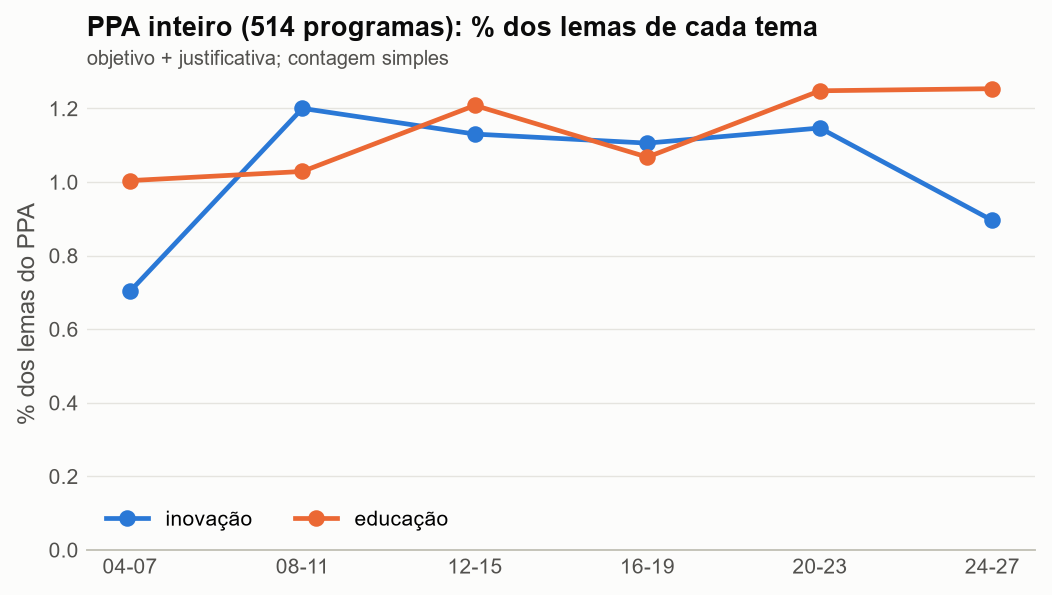

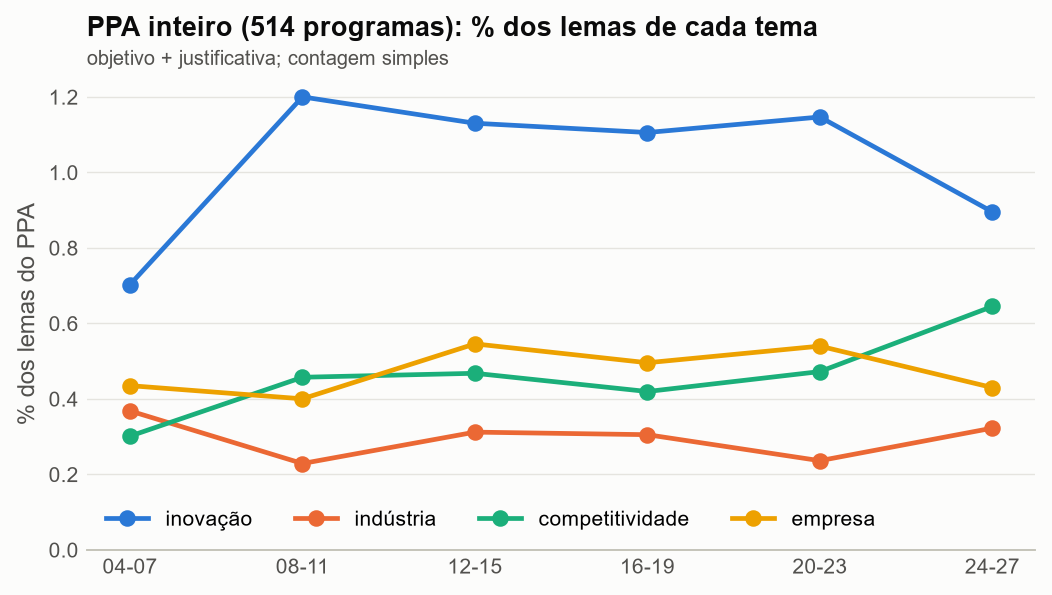

In [4]:
fig("ppa_inteiro_inovacao_x_educacao.png")
fig("ppa_inteiro_inovacao_e_industria.png")

**Leitura:** no PPA inteiro **nenhum tema muda além do acaso** (p entre 0,67 e 0,998). Inovação fica perto de 1,1% dos lemas de 2008 a 2023 e cai para 0,9% em 2024-2027; educação fica estável entre 1,0% e 1,25%; indústria, mesmo na versão ampliada, fica entre 0,2% e 0,4%, sem tendência. A palavra "indústria" aparece 4 vezes em 20 anos de planos e "industrial", 7. **Inovação e indústria não ganham força no plano como um todo.** Nos programas selecionados, só competitividade varia além do acaso (p = 0,006, como antes), e educação não aparece neles a partir de 2012-2015.

## 2. Competitividade foi substituída por inovação?

Palavras soltas "competitividade" e "inovação" (não as dimensões), % dos lemas, e a soma das duas.

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\ppa_inteiro_competitividade_x_inovacao.png


recorte,palavra,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
PPA inteiro,competitividade,"0,067","0,171","0,273","0,267","0,236","0,358"
PPA inteiro,inovação,"0,033","0,171","0,351","0,343","0,337","0,215"
PPA inteiro,soma,"0,100","0,343","0,624","0,610","0,573","0,573"
selecionados,competitividade,"0,000","0,685","0,949","1,007","0,920","2,909"
selecionados,inovação,"0,000","2,055","2,848","2,685","2,454","1,091"
selecionados,soma,"0,000","2,740","3,797","3,691","3,374","4,000"


recorte,palavra,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
PPA inteiro,competitividade,2,3,7,7,7,10
PPA inteiro,inovação,1,3,9,9,10,6
PPA inteiro,soma,3,6,16,16,17,16
selecionados,competitividade,0,1,3,3,3,8
selecionados,inovação,0,3,9,8,8,3
selecionados,soma,0,4,12,11,11,11


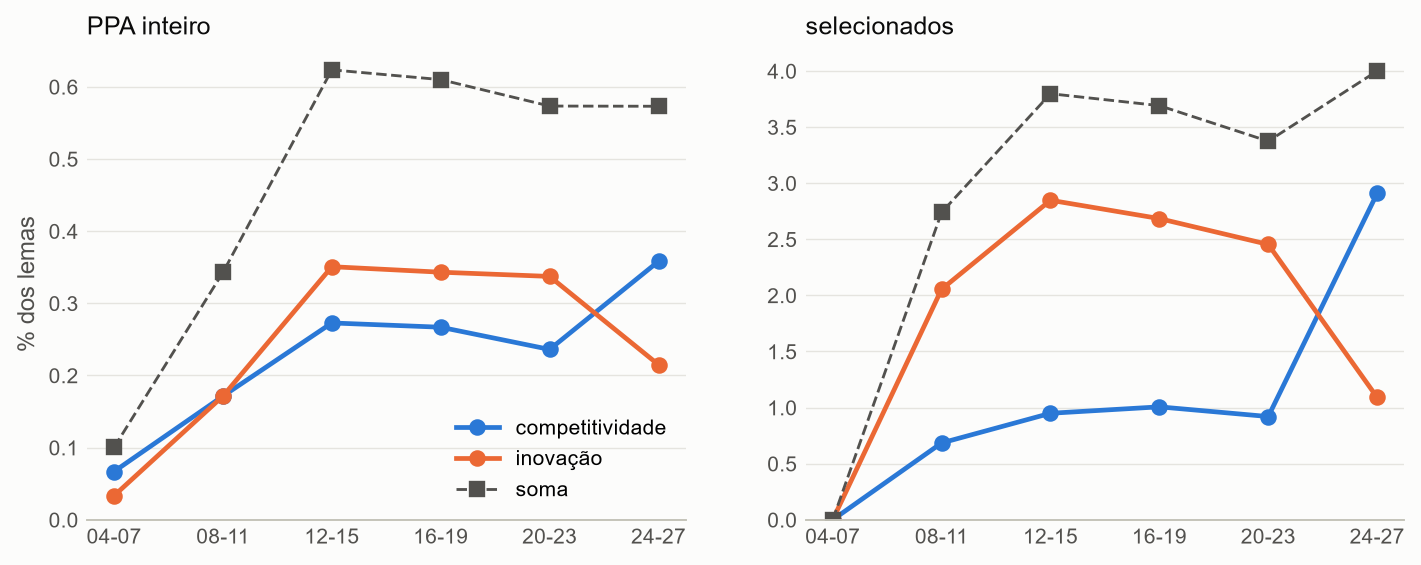

In [5]:
serie, mesmos, troca, frases = item2_comp_inov(p, f)
tabela(serie[["recorte", "palavra"] + PER], 3)
tabela(serie[["recorte", "palavra"] + [f"{q} n" for q in PER]].rename(columns=lambda c: c.replace(" n", "")))
fig("ppa_inteiro_competitividade_x_inovacao.png", 900)

Aparecem nos mesmos programas? Número de programas com cada palavra, por PPA (PPA inteiro):

In [6]:
tabela(mesmos)

periodo,programas,com_competitividade,com_inovacao,com_as_duas
2004-2007,118,2,1,0
2008-2011,65,3,2,1
2012-2015,85,7,3,2
2016-2019,87,7,4,2
2020-2023,88,6,5,1
2024-2027,86,8,5,2


Programas com alguma das duas em 2024-2027 e o que tinham em 2020-2023 (mesma série de código; vazio = programa novo):

In [7]:
tabela(troca, 0)

codigo,nome,selecionado,2024-27 competitividade,2024-27 inovação,2020-23 competitividade,2020-23 inovação
0145,"Elaboração de Planos, Estudos e Projetos de Infraestrutura",0,1,0,1,0
0200,Competitividade e Excelência Econômica,1,1,0,1,1
0230,"CTI - Fomento à Ciência, Tecnologia e Inovação",1,1,1,0,1
0310,Desenvolvimento Agropecuário e Pesqueiro,1,1,0,0,0
0320,Agricultura e Pesca Catarinense,0,0,1,0,0
0342,Revitalização da Economia Catarinense - PREC,1,1,0,1,0
0353,"Incentivo à Competitividade da Indústria, do Comércio e do Serviço",1,1,1,,
0354,"Promoção de Políticas de Trabalho, Emprego e Renda",1,1,0,,
0770,DETRAN Digital,0,0,1,0,0
0845,Gestão do Programa de Integridade e Compliance,0,0,1,0,1


Frases de cada uma no último PPA (2024-2027, PPA inteiro):

In [8]:
with pd.option_context("display.max_colwidth", None):
    display(frases.style.hide(axis="index").set_properties(subset=["frase"], **{"text-align": "left", "white-space": "normal"}))

palavra,codigo,selecionado,campo,frase
competitividade,0145,0,justificativa,Isto é fundamental para melhorar a eficiência e a competitividade da economia estadual.
competitividade,0190,0,justificativa,"Gaseificar novas infraestruturas em novos municípios, a fim de disponibilizar o gás natural para os diversos segmentos de mercado (industrial, veicular, comercial, residencial e termoelétrico), contribuindo com o aumento da competitividade da indústria catarinense e o bem estar social."
competitividade,0200,1,objetivo,"Fomentar a atividade produtiva no Estado, com vistas a melhorar a competitividade nacional e internacional das empresas catarinenses."
competitividade,0200,1,justificativa,"Visando diminuir barreiras e aumentar a competitividade catarinense, é importante fomentar investimentos, com intuito de auxiliar no desenvolvimento econômico do Estado de Santa Catarina."
competitividade,0310,1,justificativa,Necessidade de manutenção da competitividade da agricultura e pesca catarinenses para gerar oportunidade a permanência das famílias no campo e no mar.
competitividade,0342,1,objetivo,"Promover o desenvolvimento econômico sustentável através de ações para o fortalecimento de polos produtivos já existentes, criação de polos econômicos em regiões de baixo IDH, novos negócios ligados à economia verde e apoio financeiro e técnico a microempresas e empreendedores individuais (MEIs), criando assim as condições necessárias para o aumento da competitividade da economia catarinense."
competitividade,0353,1,justificativa,"A garantia da qualidade dos produtos e serviços oferecidos, contribuem para a geração de empregos, o aumento da competitividade, o crescimento sustentável e a diversificação econômica."
competitividade,0354,1,justificativa,"Estimular a qualificação e a capacitação dos trabalhadores catarinenses, permite ampliar a base de empregos qualificados, impactando no nível de renda e nos índices de competitividade global do Estado de Santa Catarina."
"competitividade, inovação",0230,1,objetivo,"Estimular, apoiar e fomentar o desenvolvimento econômico a partir da promoção da ciência, tecnologia e inovação, aumentando a produtividade e a competitividade da economia de Santa Catarina e também melhorar a prestação de serviços públicos à sociedade por meio de ações construídas conjuntamente com parceria com instituições públicas e privadas."
"competitividade, inovação",0353,1,justificativa,"Políticas públicas de fomento à competitividade e a inovação nos setores da indústria, do comércio e dos serviços promovem a melhoria da qualidade de vida da população catarinense e o equilíbrio econômico regional."


**Leitura:** nos selecionados, de 2020-2023 para 2024-2027 "inovação" cai de 8 para 3 ocorrências e "competitividade" sobe de 3 para 8; **a soma fica igual (11)**. No PPA inteiro o movimento é o mesmo e menor (inovação 10 para 6, competitividade 7 para 10, soma 17 para 16). As duas raramente aparecem no mesmo programa (1 ou 2 programas por PPA). O caso mais claro de troca é o **0200**: tinha as duas palavras em 2020-2023 e só competitividade em 2024-2027. O 0230 faz o contrário (ganha competitividade e mantém inovação), e o 0310, o 0342, o 0353 e o 0354 trazem competitividade sem histórico de inovação. Fora dos selecionados, "inovação" migra para programas de serviço público (DETRAN Digital, Integridade e Compliance). Há sinal de substituição no agregado, mas com contagens de 3 a 10 palavras; dá para descrever, não para afirmar.

## 3. Público-alvo

O campo PÚBLICO-ALVO agora é extraído (antes era só marcador de fim). Atenção: **no PDF o campo vem cortado em 50 caracteres em todos os PPAs** (ex.: "Órgãos da Administração Direta, Autarquias e Funda"). Categorias aprovadas (só as 7 propostas; o resto vai para "outros"), por regex sem acento:
- **empresas:** `empres|empreend|investidor|industri|pessoa juridica`
- **micro e pequenas empresas:** `\bmicro|pequen|individua`
- **trabalhadores:** `trabalhador|desempreg`
- **produtores rurais:** `agricult|produtor|pescador|aquicult|pecuarist|do campo|rura|agro`
- **municípios:** `municipi|prefeit`
- **instituições de pesquisa:** `\bcti\b|universidade|pesquis`
- **sociedade em geral:** `popula|polpula|cidad|sociedade|usuario|consumidor|geral|turist`

**Demanda (quem recebe):** % dos programas do PPA em cada categoria (um programa pode cair em mais de uma). **Oferta (quem executa):** % dos programas por área do órgão responsável (regras em `AREAS`).

In [9]:
tab_pub, demanda, oferta = item3_publico(p)
tabela(demanda, 1)
tabela(oferta, 1)

recorte,categoria,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
PPA inteiro,empresas,"9,3","3,1","5,9","5,7","9,1","8,1"
PPA inteiro,micro e pequenas empresas,"1,7","0,0","1,2","1,1","1,1","1,2"
PPA inteiro,trabalhadores,"0,0","0,0","0,0","0,0","0,0","0,0"
PPA inteiro,produtores rurais,"16,9","6,2","5,9","5,7","4,5","3,5"
PPA inteiro,municípios,"2,5","1,5","0,0","1,1","1,1","3,5"
PPA inteiro,instituições de pesquisa,"0,8","0,0","0,0","0,0","1,1","1,2"
PPA inteiro,sociedade em geral,"44,9","44,6","41,2","44,8","54,5","55,8"
PPA inteiro,outros,"32,2","44,6","49,4","43,7","37,5","38,4"
selecionados,empresas,"44,4","50,0","62,5","71,4","71,4","57,1"
selecionados,micro e pequenas empresas,"0,0","0,0","12,5","14,3","14,3","14,3"


recorte,area,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
PPA inteiro,CT&I,"0,0","0,0","0,0","0,0","1,1","1,2"
PPA inteiro,agricultura e pesca,"14,4","6,2","5,9","5,7","4,5","3,5"
PPA inteiro,"assistência, trabalho e habitação","7,6","7,7","4,7","4,6","1,1","1,2"
PPA inteiro,"cultura, turismo e esporte","9,3","6,2","3,5","3,4","5,7","7,0"
PPA inteiro,desenvolvimento econômico e indústria,"4,2","6,2","9,4","9,2","10,2","8,1"
PPA inteiro,educação,"11,0","7,7","9,4","9,2","9,1","9,3"
PPA inteiro,"gestão (administração, fazenda, planejamento, governo)","22,9","20,0","24,7","25,3","20,5","19,8"
PPA inteiro,"infraestrutura, energia e saneamento","14,4","21,5","14,1","13,8","17,0","16,3"
PPA inteiro,meio ambiente e defesa civil,"0,0","0,0","2,4","3,4","4,5","5,8"
PPA inteiro,outros poderes,"7,6","12,3","10,6","9,2","11,4","15,1"


Tabela programa x PPA x público-alvo dos selecionados (a do PPA inteiro está em `saidas/ppa_inteiro_publico_alvo.csv`):

In [10]:
sel_pub = tab_pub[tab_pub.selecionado == 1].pivot_table(index="codigo", columns="periodo", values="publico_alvo", aggfunc="first").reindex(columns=PER).fillna("")
display(sel_pub)

periodo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
codigo,,,,,,
0200,,Empreendedores,Empreendedores,Empreendedores,Empreendedores e empresas,Municípios atendidos
0210,,Administradores públicos,Administradores públicos,Administradores públicos,Sociedade catarinense,População catarinense
0212,,,Investidores Internacionais e população em geral,Investidores Internacionais,Organismos e Organizações Internacionais,
0230,"Agricultores, Aqüicultores , Pescadores, Famílias",Empreendedores,Empreendedores,Empreendedores,Instituições de CTI; Empresas; Governo; Sociedade,Instituições de CTI; Empresas; Governo; Sociedade
0250,,Cidadãos que não possuem acesso à internet,Cidadãos que não possuem acesso à internet,,,
0310,,,Produtores rurais,Produtores rurais,Produtores rurais e atores da Agroindústria,Produtores rurais e atores da Agroindústria
0342,,,Micro empresas e empreendedores individuais,Micro empresas e empreendedores individuais,Microempresas e empreendedores individuais,Microempresas e empreendedores individuais
0346,,,Empreendedores Catarinenses,Empreendedores Catarinenses,Empreendedores catarinenses,
0353,,,,,,Empresas


**Leitura:** **"trabalhadores" não aparece como público-alvo em nenhum programa de nenhum PPA**, nem no 0354 (Trabalho, Emprego e Renda), cujo público é "População Catarinense". Nos selecionados, empresas e empreendedores são o público de 44% dos programas em 2004-2007 e de 50% a 71% depois. Em 2024-2027 o **0200 muda de "Empreendedores e empresas" para "Municípios atendidos"**, coerente com o peso do crédito do BADESC a prefeituras. No PPA inteiro, "sociedade em geral" responde por 41% a 56% dos programas e produtores rurais caem de 17% (2004-2007) para 3,5% (2024-2027), pela consolidação dos programas agrícolas. Pelo lado da oferta, a política industrial sai da área de gestão (Planejamento, Fazenda, Gabinete) em 2004-2007 para o desenvolvimento econômico a partir de 2008, e ganha um braço de CT&I (FAPESC, depois Secretaria de CT&I) em 2020-2027. "Outros" é grande no PPA inteiro (32% a 49%) porque servidores, órgãos públicos e estudantes não têm categoria própria.

## 4. Subações e metas financeiras

A subação é a política de fato. Regras aprovadas (nome da subação, sem acento; inclusão e exclusão):
- **inovação:** inclui `inova|cientific|\bciencia|\bcti\b|pesquisa e desenvolvimento|desenvolvimento tecnologic|incubad|parques? tecnologic|startup|base tecnologica|bolsas? de pesquisa|pesquisa agropecuaria`; exclui `tecnologia da informac|informatica`
- **indústria e empresa:** inclui `industri|empresa|empreend|\bapls?\b|arranjos? produtiv|cadeias? produtiv|exporta|microcredito|fundo de aval|subvenc\w* econom`; exclui `amortizac|encargos|co-?financ|penitenciaria|municipi|usina|\bpch`

Valores: 2004-2007 e 2008-2011 trazem um ano só; 2012-2027, o quadriênio. Por isso a comparação é em **% do total do próprio PPA**. Valores nominais. Todas as subações do PPA, não só as dos selecionados.

In [11]:
lista, variaveis, por_prog, orgaos, unidades, mudancas = item4_subacoes(p, s)
v = variaveis.assign(valor_mi=variaveis.valor / 1e6)
tabela(v[["tema", "periodo", "base", "subacoes", "programas", "valor_mi", "pct_ppa", "pct_ppa_fora_dos_selecionados"]], 2)

tema,periodo,base,subacoes,programas,valor_mi,pct_ppa,pct_ppa_fora_dos_selecionados
indústria e empresa,2004-2007,1 ano,101,12,"107,73","0,61","0,07"
indústria e empresa,2008-2011,1 ano,34,10,"464,84","1,79","1,11"
indústria e empresa,2012-2015,quadriênio,26,11,"1.774,43","1,39","0,79"
indústria e empresa,2016-2019,quadriênio,21,9,"1.283,78","0,94","0,06"
indústria e empresa,2020-2023,quadriênio,18,9,"1.236,42","0,66","0,06"
indústria e empresa,2024-2027,quadriênio,22,8,"1.445,64","0,54","0,02"
inovação,2004-2007,1 ano,88,11,"154,43","0,88","0,18"
inovação,2008-2011,1 ano,26,11,"165,42","0,64","0,19"
inovação,2012-2015,quadriênio,20,9,"679,18","0,53","0,14"
inovação,2016-2019,quadriênio,18,8,"833,80","0,61","0,23"


Variáveis criadas (valor e % por tema e PPA) em `saidas/ppa_inteiro_variaveis_tema.csv`; lista completa das subações em `saidas/ppa_inteiro_subacoes_tema.csv`. Comparação entre programas do mesmo tema (% do PPA):

In [12]:
tabela(por_prog[por_prog.total > 0.02].drop(columns="total"), 3)

tema,programa,nome (último PPA),2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
indústria e empresa,0200,Competitividade e Excelência Econômica,"0,029","0,674","0,523","0,716","0,411","0,270"
indústria e empresa,0530,Pró-Emprego e Renda,"0,513","0,964","0,698","0,000","0,000","0,000"
indústria e empresa,0230,"CTI - Fomento à Ciência, Tecnologia e Inovação","0,002","0,001","0,000","0,103","0,044","0,109"
indústria e empresa,0342,Revitalização da Economia Catarinense - PREC,"0,000","0,000","0,020","0,002","0,150","0,085"
indústria e empresa,0310,Desenvolvimento Agropecuário e Pesqueiro,"0,000","0,017","0,051","0,044","0,000","0,000"
indústria e empresa,0188,"Concessões, Participações e Parcerias Público-Privadas","0,000","0,000","0,058","0,051","0,002","0,001"
indústria e empresa,0120,Integração Logística,"0,000","0,108","0,000","0,000","0,000","0,000"
indústria e empresa,0353,"Incentivo à Competitividade da Indústria, do Comércio e","0,000","0,000","0,000","0,000","0,000","0,058"
indústria e empresa,0190,Expansão do Gás Natural,"0,000","0,000","0,014","0,006","0,020","0,000"
indústria e empresa,0140,Reabilitação e Aumento de Capacidade de Rodovias - Estr,"0,000","0,000","0,000","0,000","0,026","0,013"


Órgão responsável dos programas selecionados, por série, e siglas das unidades que aparecem nas subações (a sigla só existe em parte das subações; SDR = subações regionalizadas):

In [13]:
display(orgaos.fillna(""))
display(unidades.fillna(""))

periodo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
serie,,,,,,
0200,Secretaria de Estado do Planejamento,Secretaria de Estado do Desenvolvimento Econôm...,Secretaria de Estado do Desenvolvimento Econôm...,Secretaria de Estado do Desenvolvimento Econôm...,Agência de Fomento do Estado de Santa Catarina...,Agência de Fomento do Estado de Santa Catarina...
0210,Secretaria de Estado do Planejamento,Secretaria de Estado do Planejamento,Secretaria de Estado do Planejamento,Secretaria de Estado do Planejamento,Secretaria de Estado do Desenvolvimento Econôm...,Superintendência de Desenvolvimento da Região ...
0212,Gabinete do Governador do Estado,,Gabinete do Governador do Estado,Gabinete do Governador do Estado,Casa Civil,
0230,"Secretaria de Estado da Educação, Ciência e Te...",Secretaria de Estado do Desenvolvimento Econôm...,Secretaria de Estado do Desenvolvimento Econôm...,Secretaria de Estado do Desenvolvimento Econôm...,Fundação de Amparo à Pesquisa e Inovação do Es...,"Secretaria de Estado da Ciência, Tecnologia e ..."
0250,"Secretaria de Estado da Educação, Ciência e Te...",Secretaria de Estado da Educação,Secretaria de Estado da Educação,,,
0310,Secretaria de Estado da Agricultura e Desenvol...,,Secretaria de Estado da Agricultura e da Pesca,Secretaria de Estado da Agricultura e da Pesca,"Secretaria de Estado da Agricultura, da Pesca ...",Secretaria de Estado da Agricultura - SAR
0342,Secretaria de Estado da Fazenda,,Secretaria de Estado do Desenvolvimento Econôm...,Secretaria de Estado do Desenvolvimento Econôm...,Secretaria de Estado do Desenvolvimento Econôm...,Secretaria de Estado da Indústria do Comércio ...
0346,,,Secretaria de Estado do Desenvolvimento Econôm...,Secretaria de Estado do Desenvolvimento Econôm...,Secretaria de Estado do Desenvolvimento Econôm...,
0353,,,,,,Secretaria de Estado da Indústria do Comércio ...


periodo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
serie,,,,,,
0200,"FADESC, SDR","SAI, SDS, SDR","BADESC, CODESC, SDR","BADESC, CODESC, SDR","BADESC, FAE/SC","BADESC, FAE/SC, FUNDO, IAZPE"
0210,,"SC, SPG","CODESC, SPG, SDR",SDR,SDE,SUDESC
0212,,,,,SAI,
0230,,"ENA, SDS, SDR","FAPESC, FUNDOSOCIAL, UDESC, SDR","UDESC, SDR","SAPIENS, SEA","ENA, TIC"
0250,,"SAR, SDR","SAR, SED, SDR",,,
0310,SDR,,"CEASA, CIDASC, EPAGRI, FDR, FSA, SAR, SDR","CIDASC, EPAGRI, FDR, FSA, SDR",EPAGRI,"EPAGRI, SAQ"
0342,,,"SDS, SDR","SDS, SDR",SDE,SICOS
0346,,,SDS,SDR,,
0353,,,,,,SC


O que muda nas subações do mesmo programa entre PPAs consecutivos (comparação pelo código de 6 dígitos da subação):

In [14]:
tabela(mudancas, 1)

serie,transição,subações antes,subações depois,mantidas (mesmo código),% do valor em subações mantidas,maiores subações novas
0200,2004-2007 → 2008-2011,54,38,0,"0,0",Apoio creditício ao desenvolvimento dos municípios - unidade | Apoio creditício às empresas de pequeno porte - unidade | Apoio creditício às microempresas - Badesc unidade
0200,2008-2011 → 2012-2015,38,13,8,"99,2","Ordenamento da ocupação territorial e criação de complexo tu | Apoio a pequena e média empresa - SDR - Dionísio Cerqueira O | Impl centro dist produtos da cadeia produtiva agrícola, ind"
0200,2012-2015 → 2016-2019,13,9,7,"93,6",Subvenção Econômica a Empresas Subvenção paga unidade | AP - Fortalecer pequenas empresas e indústrias locais - SDR
0200,2016-2019 → 2020-2023,9,12,4,"77,6",Implantação do Fundo de Aval do Estado de Santa Catarina - F | Revitalização/implantação de infraestrutura da IAZPE Obra ex | Apoio às ações de infraestrutura e inovação tecnológica para
0200,2020-2023 → 2024-2027,12,11,10,"97,4",Revitalização/implantação de infraestrutura - IAZPE Obra exe
0210,2004-2007 → 2008-2011,6,37,0,"0,0","Projetos de engenharia e de reabilitação e aumento de km | Estudos, projetos e implantação de parcerias no setor unidad | Levantamentos, estudos e projetos diversos - Deinfra unidade"
0210,2008-2011 → 2012-2015,37,56,1,"0,0",Ações estratégicas de desenvolvimento regional - SDR - Chape | Avaliação de políticas públicas - SPG Projeto elaborado unid | Gestão do ordenamento territorial do estado - SPG Plano elab
0210,2012-2015 → 2016-2019,56,37,36,"96,3",Plano de Desenvolvimento Urbano Integrado da RM Florianópoli
0210,2016-2019 → 2020-2023,37,4,0,"0,0",Emendas parlamentares impositivas do FUNDO SOCIAL Projeto ex | Emendas parlamentares impositivas do Fundam Projeto executad | Programa para a redução das desigualdades sociais - SDE Muni
0210,2020-2023 → 2024-2027,4,10,1,"88,2","Implantação e/ou requal. de terminais, estações e demais inf | Implantação de tec. alternativas visando à sustent. nas polí | Elaboração de plano de desenvolvimento integrado para unidad"


**Leitura:** as subações de **indústria e empresa** valem 0,61% do PPA em 2004-2007, 1,79% em 2008-2011 e caem até 0,54% em 2024-2027; as de **inovação** caem de 0,88% para 0,41%. As duas perdem peso enquanto o discurso de competitividade sobe. Em 2008-2015 uma parte grande das subações de indústria e empresa está **fora da lista** de selecionados, quase toda no **0530 Pró-Emprego e Renda** (crédito), que é selecionado só em 2004-2007; de 2016 em diante quase tudo está dentro da lista. As trocas de órgão vêm junto com troca de subações: o 0230 manteve só 11,5% do valor em subações que já existiam quando passou da FAPESC para a Secretaria de CT&I; o 0342, 8% na passagem para 2020-2023. A comparação por código subestima a continuidade se a subação for renumerada.

## 5. Estabilidade da linguagem: texto copiado entre PPAs

Para cada frase de objetivo e justificativa, a maior similaridade (SequenceMatcher, texto sem acento e pontuação) com qualquer frase do PPA anterior. **Igual ou quase igual: similaridade de 0,9 ou mais**; idêntica: 1. A medida é a % dos lemas do PPA que estão nessas frases. Tipo de transição (reeleição ou troca de governador) não sai dos documentos: [verificar].

In [15]:
trans, prog_copia, comp_reescrito = item5_copia(p, f)
tabela(trans, 1)

transição,governo,recorte,% lemas em frases idênticas,"% lemas em frases iguais ou quase (≥ 0,9)"
2004-2007 → 2008-2011,reeleição (mesmo governador) [verificar],PPA inteiro,"11,4","20,0"
2004-2007 → 2008-2011,reeleição (mesmo governador) [verificar],selecionados,"0,0","20,5"
2008-2011 → 2012-2015,troca de governador [verificar],PPA inteiro,"38,4","43,2"
2008-2011 → 2012-2015,troca de governador [verificar],selecionados,"45,6","45,6"
2012-2015 → 2016-2019,reeleição (mesmo governador) [verificar],PPA inteiro,"82,4","83,0"
2012-2015 → 2016-2019,reeleição (mesmo governador) [verificar],selecionados,"79,6","79,6"
2016-2019 → 2020-2023,troca de governador [verificar],PPA inteiro,"21,9","24,9"
2016-2019 → 2020-2023,troca de governador [verificar],selecionados,"26,7","32,5"
2020-2023 → 2024-2027,troca de governador [verificar],PPA inteiro,"67,8","74,1"
2020-2023 → 2024-2027,troca de governador [verificar],selecionados,"20,4","31,0"


Índice de competitividade (dimensão, % dos lemas) com todo o texto e só com as frases reescritas (2004-2007 conta inteiro como novo, porque não há PPA anterior na base):

In [16]:
tabela(comp_reescrito[["recorte", "texto"] + PER], 2)
tabela(comp_reescrito[["recorte", "texto"] + [f"{q} ocorr" for q in PER]].rename(columns=lambda c: c.replace(" ocorr", "")))

recorte,texto,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
PPA inteiro,todo o texto,"0,30","0,46","0,47","0,42","0,47","0,65"
PPA inteiro,só frases reescritas,"0,30","0,43","0,34","0,00","0,36","1,52"
selecionados,todo o texto,"0,00","1,37","2,22","2,01","1,84","4,38"
selecionados,só frases reescritas,"0,00","1,72","1,74","0,00","1,82","5,29"


recorte,texto,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
PPA inteiro,todo o texto,9,8,12,11,14,18
PPA inteiro,só frases reescritas,9,6,5,0,8,11
selecionados,todo o texto,0,2,7,6,6,12
selecionados,só frases reescritas,0,2,3,0,4,10


% dos lemas copiados por programa selecionado:

In [17]:
tabela(prog_copia[prog_copia.selecionado == 1].pivot_table(index="codigo", columns="periodo", values="% lemas copiados").reset_index(), 0)

codigo,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
0200,0,100,100,0,23
0210,57,100,100,0,0
0212,,0,0,0,
0230,0,0,62,0,0
0250,52,100,,,
0310,,100,100,30,71
0342,,0,100,100,100
0346,,0,100,100,
0353,,,,,0
0354,,,,,0


**Leitura:** a cópia não segue o tipo de transição. A reeleição de 2015 [verificar] tem a maior cópia (83% dos lemas), mas a de 2007 [verificar] tem 20% (mudou o formato e os textos de 2004-2007 são curtos). Nas trocas de governador [verificar], a cópia vai de 25% (2019, que coincide com o novo formato de indicadores) a **74% (2023)**. O dado mais forte é a diferença entre o plano e a política industrial em 2024-2027: o plano repete 74% do texto anterior, mas **os programas selecionados repetem só 31%**. A alta de competitividade está no texto novo: só com frases reescritas, a dimensão vai de 1,8% para **5,3% dos lemas** nos selecionados (de 4 para 10 ocorrências). Em 2016-2019 quase tudo é cópia, e as frases reescritas não têm nenhuma ocorrência.

## 6. Parte qualitativa

### 6.1 Fichas dos programas selecionados

Uma ficha por programa e PPA em `saidas/fichas_programas_selecionados.md`: órgão, público-alvo, objetivo, principais subações com % do valor do programa. "O que não faz" fica para a leitura. Exemplo (série 0200):

In [18]:
gov, entra_sai, orc_area, orc_area_sem = item6_fichas(p, s)
txt = (S / "fichas_programas_selecionados.md").read_text(encoding="utf-8")
display(Markdown(txt.split("## Série 0200")[1].split("## Série")[0]))


### 0580 Promoção da Competitividade da Economia Catarinense (2004-2007)

- **Órgão responsável:** Secretaria de Estado do Planejamento
- **Público-alvo (como no PDF, até 50 caracteres):** Empreendedores Catarinenses
- **O que é / propósito (objetivo):** Fomentar a atividade produtiva no estado.
- **Subações:** 54; soma 86,9 mi (1 ano)
- **Principais subações (o que faz):**
  - Integralização do Fundo Garantidor das Parcerias % de Realização (46% do programa)
  - Equalização de Encargos Financeiros Unidade (44% do programa)
  - Implementação da ZPE/SC, em Imbituba - 1ª Etapa m2 (2% do programa)
  - Desenvolvimento do Estado por Meio de Projetos Unidade (2% do programa)
  - Apoio às Micro e Pequenas Empresas dos Municípios Unidade (1% do programa)
- **O que não faz:** [preencher na leitura]

### 0200 Competitividade e Excelência Econômica (2008-2011)

- **Órgão responsável:** Secretaria de Estado do Desenvolvimento Econômico Sustentável
- **Público-alvo (como no PDF, até 50 caracteres):** Empreendedores
- **O que é / propósito (objetivo):** Fomentar a atividade produtiva no estado e promover a diversificação do padrão tecnológico da produção de bens e serviços catarinenses com base na inovação de modo a melhorar a competitividade nacional e internacional.
- **Subações:** 38; soma 346,8 mi (1 ano)
- **Principais subações (o que faz):**
  - Apoio creditício ao desenvolvimento dos municípios - unidade (35% do programa)
  - Apoio creditício às empresas de pequeno porte - unidade (12% do programa)
  - Apoio creditício às microempresas - Badesc unidade (12% do programa)
  - Apoio creditício às empresas de grande porte - Badesc unidade (11% do programa)
  - Apoio creditício às empresas de médio porte - Badesc unidade (11% do programa)
- **O que não faz:** [preencher na leitura]

### 0200 Competitividade e Excelência Econômica (2012-2015)

- **Órgão responsável:** Secretaria de Estado do Desenvolvimento Econômico Sustentável
- **Público-alvo (como no PDF, até 50 caracteres):** Empreendedores
- **O que é / propósito (objetivo):** Fomentar a atividade produtiva no estado e promover a diversificação do padrão tecnológico da produção de bens e serviços catarinenses com base na inovação de modo a melhorar a competitividade nacional e internacional.
- **Subações:** 13; soma 1.450,2 mi (quadriênio)
- **Principais subações (o que faz):**
  - Apoio creditício ao desenvolvimento dos municípios - BADESC Operação de crédito realizada unidade (53% do programa)
  - Apoio creditício às empresas de médio e grande porte - BADESC Operação de crédito realizada unidade (39% do programa)
  - Apoio creditício às micro e pequenas empresas - BADESC Operação de crédito realizada unidade (4% do programa)
  - Apoio creditício ao sistema de microcrédito - BADESC Operação de crédito realizada unidade (3% do programa)
  - Ordenamento da ocupação territorial e criação de complexo turístico e tecnológico - Obra executada unidade (1% do programa)
- **O que não faz:** [preencher na leitura]

### 0200 Competitividade e Excelência Econômica (2016-2019)

- **Órgão responsável:** Secretaria de Estado do Desenvolvimento Econômico Sustentável
- **Público-alvo (como no PDF, até 50 caracteres):** Empreendedores
- **O que é / propósito (objetivo):** Fomentar a atividade produtiva no estado e promover a diversificação do padrão tecnológico da produção de bens e serviços catarinenses com base na inovação de modo a melhorar a competitividade nacional e internacional.
- **Subações:** 9; soma 1.443,7 mi (quadriênio)
- **Principais subações (o que faz):**
  - Apoio creditício às empresas de médio e grande porte - BADESC Operação de crédito realizada unidade (33% do programa)
  - Apoio creditício ao desenvolvimento dos municípios - BADESC Operação de crédito realizada unidade (32% do programa)
  - Apoio creditício às micro e pequenas empresas - BADESC Operação de crédito realizada unidade (22% do programa)
  - Subvenção Econômica a Empresas Subvenção paga unidade (6% do programa)
  - Apoio creditício ao sistema de microcrédito - BADESC Operação de crédito realizada unidade (6% do programa)
- **O que não faz:** [preencher na leitura]

### 0200 Competitividade e Excelência Econômica (2020-2023)

- **Órgão responsável:** Agência de Fomento do Estado de Santa Catarina S.A.
- **Público-alvo (como no PDF, até 50 caracteres):** Empreendedores e empresas
- **O que é / propósito (objetivo):** Fomentar a atividade produtiva no Estado, facilitar e dar publicidade dos atos constitutivos empresariais, com vistas a melhorar a competitividade nacional e internacional das empresas catarinenses. Promover a diversificação do padrão tecnológico da produção de bens e serviços baseados em inovação, buscando excelência econômica. Assegurar o registro de leiloeiros, tradutores e intérpretes comercia
- **Subações:** 12; soma 1.458,9 mi (quadriênio)
- **Principais subações (o que faz):**
  - Apoio creditício ao desenvolvimento dos municípios - BADESC Operação de crédito realizada unidade (40% do programa)
  - Apoio creditício às empresas de médio e grande porte - BADESC Operação de crédito realizada unidade (22% do programa)
  - Implantação do Fundo de Aval do Estado de Santa Catarina - FAE/SC Operação de crédito realizada unidade (11% do programa)
  - Apoio creditício às micro e pequenas empresas - BADESC Operação de crédito realizada unidade (10% do programa)
  - Apoio creditício ao sistema de microcrédito - BADESC Operação de crédito realizada unidade (6% do programa)
- **O que não faz:** [preencher na leitura]

### 0200 Competitividade e Excelência Econômica (2024-2027)

- **Órgão responsável:** Agência de Fomento do Estado de Santa Catarina S.A.
- **Público-alvo (como no PDF, até 50 caracteres):** Municípios atendidos
- **O que é / propósito (objetivo):** Fomentar a atividade produtiva no Estado, com vistas a melhorar a competitividade nacional e internacional das empresas catarinenses.
- **Subações:** 11; soma 1.171,6 mi (quadriênio)
- **Principais subações (o que faz):**
  - Apoio creditício às empresas de médio e grande porte - BADESC Operação de crédito unidade (30% do programa)
  - Apoio creditício ao desenvolvimento dos municípios - BADESC Operação de crédito unidade (28% do programa)
  - Apoio creditício às micro e pequenas empresas - BADESC Operação de crédito unidade (20% do programa)
  - Ampliação do Fundo de Aval do Estado de Santa Catarina - FAE/SC Aporte realizado unidade (5% do programa)
  - Subsídio financeiro de juros e encargos para ações de geração de empregos e negócios - FUNDO SOCIAL Projeto ap (5% do programa)
- **O que não faz:** [preencher na leitura]



### 6.2 Alternância de governos e planejamento

Governos: [verificar] (não saem dos PPAs). Órgão coordenador do PPA segundo a SEF: Desenvolvimento Econômico até 2003, Planejamento de 2003 a 2011, Fazenda desde 2011. Secretarias dos selecionados e contagens: dos PDFs.

In [19]:
with pd.option_context("display.max_colwidth", None):
    display(gov.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))
tabela(entra_sai, 1)

periodo,ano_elaboracao,governo,orgao_coordenador_ppa,secretarias dos selecionados,programas no PPA,órgãos responsáveis distintos
2004-2007,2003,"Luiz Henrique da Silveira (PMDB), 1º mandato [verificar]",Planejamento,"Gabinete do Governador do Estado; Secretaria de Estado da Agricultura e Desenvolvimento Rural; Secretaria de Estado da Educação, Ciência e Tecnologia; Secretaria de Estado da Fazenda; Secretaria de Estado do Desenvolvimento Social, Trabalho e Renda; Secretaria de Estado do Planejamento",118,22
2008-2011,2007,"Luiz Henrique da Silveira (PMDB), 2º mandato [verificar]",Planejamento,Secretaria de Estado da Educação; Secretaria de Estado do Desenvolvimento Econômico Sustentável; Secretaria de Estado do Planejamento,65,19
2012-2015,2011,"Raimundo Colombo (DEM, depois PSD), 1º mandato [verificar]",Fazenda,Gabinete do Governador do Estado; Secretaria de Estado da Agricultura e da Pesca; Secretaria de Estado da Educação; Secretaria de Estado do Desenvolvimento Econômico Sustentável; Secretaria de Estado do Planejamento,85,21
2016-2019,2015,"Raimundo Colombo (PSD), 2º mandato [verificar]",Fazenda,Gabinete do Governador do Estado; Secretaria de Estado da Agricultura e da Pesca; Secretaria de Estado do Desenvolvimento Econômico Sustentável; Secretaria de Estado do Planejamento,87,19
2020-2023,2019,"Carlos Moisés da Silva (PSL), 1º mandato [verificar]",Fazenda,"Agência de Fomento do Estado de Santa Catarina S.A.; Casa Civil; Fundação de Amparo à Pesquisa e Inovação do Estado de Santa Catarina; Secretaria de Estado da Agricultura, da Pesca e do Desenvolvimento Rural; Secretaria de Estado do Desenvolvimento Econômico Sustentável",88,38
2024-2027,2023,"Jorginho Mello (PL), 1º mandato [verificar]",Fazenda,"Agência de Fomento do Estado de Santa Catarina S.A.; Secretaria de Estado da Agricultura - SAR; Secretaria de Estado da Ciência, Tecnologia e Inovação; Secretaria de Estado da Indústria do Comércio e do Serviço; Superintendência de Desenvolvimento da Região Metropolitana de Santa Catarina - SUDESC",86,41


transição,governo,mantidos,entram,saem,% renovado
2008-2011 → 2012-2015,troca de governador [verificar],54,31,11,"36,5"
2012-2015 → 2016-2019,reeleição (mesmo governador) [verificar],76,11,9,"12,6"
2016-2019 → 2020-2023,troca de governador [verificar],64,24,23,"27,3"
2020-2023 → 2024-2027,troca de governador [verificar],77,9,11,"10,5"


Rascunho de seção (também em `docs/rascunho-governos-planejamento.md`):

In [20]:
display(Markdown((RAIZ / "docs" / "rascunho-governos-planejamento.md").read_text(encoding="utf-8").split("## Texto")[1].split("## Pendências")[0]))



O Plano Plurianual de Santa Catarina não é escrito por um único autor. O órgão central de planejamento define o formato e consolida o documento, mas cada programa é redigido pela secretaria ou entidade responsável por ele. Segundo a Secretaria de Estado da Fazenda, essa coordenação passou pela Secretaria de Desenvolvimento Econômico até 2003, pela Secretaria do Planejamento de 2003 a 2011 e pela própria Fazenda desde 2011. Os seis planos analisados foram elaborados no primeiro ano de cada mandato: o de 2004-2007 e o de 2008-2011 sob Luiz Henrique da Silveira [verificar]; o de 2012-2015 e o de 2016-2019 sob Raimundo Colombo [verificar]; o de 2020-2023 sob Carlos Moisés da Silva [verificar]; e o de 2024-2027 sob Jorginho Mello [verificar]. Há, portanto, duas transições por reeleição (2007 e 2015) e três por troca de governador (2011, 2019 e 2023) [verificar].

O formato do documento muda com a coordenação. Os planos de 2004-2007 e 2008-2011, coordenados pelo Planejamento, seguem o mesmo leiaute: rótulos com inicial maiúscula ("Órgão Responsável", "Público Alvo"), valores de um único exercício em duas colunas (OGE e OF) e subações regionalizadas pelas Secretarias de Desenvolvimento Regional. A partir de 2012-2015, já sob a Fazenda, o plano passa a trazer a meta financeira do quadriênio e uma tabela de indicadores com valor de referência; em 2016-2019 os valores são separados entre recursos do Tesouro e de outras fontes; em 2020-2023 e 2024-2027 os indicadores ganham polaridade e meta ao final do plano. O número de programas cai de 118 em 2004-2007 para 65 em 2008-2011 e se estabiliza entre 85 e 88 a partir de 2012. O número de órgãos responsáveis por programas, que oscilava entre 19 e 22 até 2016-2019, sobe para 38 em 2020-2023 e 41 em 2024-2027, o que sugere que a responsabilidade passou a ser atribuída a unidades mais específicas, como agências, fundações e empresas estatais.

A troca de governo deixa marca na estrutura de programas, mas não de forma uniforme. Comparando os códigos de programa entre planos consecutivos, a parcela de programas novos foi de 36,5% na passagem de 2008-2011 para 2012-2015, de 12,6% na reeleição de 2015 e de 27,3% na passagem para 2020-2023. Na passagem para 2024-2027, também uma troca de governador [verificar], apenas 10,5% dos programas são novos. O texto segue o mesmo padrão: a parcela dos lemas do plano que está em frases iguais ou quase iguais às do plano anterior é de 83% na reeleição de 2015, de 25% em 2020-2023 e volta a 74% em 2024-2027. A troca de 2019 coincide com a mudança de formato dos indicadores, de modo que não é possível separar o efeito do novo governo do efeito do novo leiaute.

Nos programas de política industrial o comportamento é diferente do restante do plano. Em 2024-2027, enquanto 74% do texto do plano inteiro repete o plano anterior, apenas 31% do texto dos programas de política industrial é repetido. A reescrita acompanha uma reorganização das secretarias: o 0342 (PREC), o 0353 e o 0354 passam à Secretaria de Estado da Indústria, do Comércio e do Serviço, o 0230 passa da FAPESC para a Secretaria de Estado da Ciência, Tecnologia e Inovação e o 0200 já estava, desde 2020-2023, sob a Agência de Fomento (BADESC). A criação dessas secretarias no início do novo governo [verificar datas e leis de criação] é a explicação mais provável para a reescrita concentrada na política industrial. É também no texto reescrito que aparece a alta da linguagem de competitividade: considerando só as frases novas, a dimensão competitividade passa de 1,8% dos lemas em 2020-2023 para 5,3% em 2024-2027 nos programas selecionados.

Movimentos semelhantes aparecem antes. O 0200 começa sob o Planejamento em 2004-2007 (como 0580), passa ao Desenvolvimento Econômico de 2008 a 2019 e à Agência de Fomento a partir de 2020. O 0230 sai da Secretaria da Educação, Ciência e Tecnologia em 2004-2007 (como 0490) para o Desenvolvimento Econômico, depois para a FAPESC e, por fim, para a nova secretaria de ciência e tecnologia. Cada mudança de responsável é acompanhada de troca de subações: no 0230, só 11,5% do valor de 2024-2027 está em subações que já existiam em 2020-2023.

A leitura que esses dados autorizam é limitada. O PPA registra o que cada secretaria escreve e o que o órgão central aceita consolidar, e a repetição de texto pode refletir tanto continuidade de política quanto economia de esforço na elaboração. A troca de governo parece importar menos que a troca de secretaria responsável pelo programa, mas essa hipótese depende de confirmar as datas de criação e extinção das secretarias.



### 6.3 Para onde o governo quer ir: peso no orçamento por área

% do valor das subações do PPA, por área do órgão responsável pelo programa. Primeira tabela: valores como estão; segunda: sem pessoal e emendas parlamentares (mesmos padrões de `orcamento_ajustado.py`, retirados do numerador e do denominador).

In [21]:
tabela(orc_area.reset_index(), 2)
tabela(orc_area_sem.reset_index(), 2)

area,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
"gestão (administração, fazenda, planejamento, governo)","34,05","54,62","58,61","56,42","40,84","41,16"
educação,"14,17","4,42","8,41","3,90","12,86","14,80"
outros poderes,"7,50","10,37","9,18","12,55","11,67","11,94"
"segurança, justiça e prisional","1,54","0,99","1,97","9,15","11,08","10,55"
"infraestrutura, energia e saneamento","24,79","15,86","9,82","6,36","10,19","8,80"
saúde,"6,48","7,43","6,23","7,97","8,45","7,62"
agricultura e pesca,"2,37","1,05","0,77","0,42","1,67","1,67"
meio ambiente e defesa civil,"0,00","0,00","0,57","0,52","0,36","1,22"
desenvolvimento econômico e indústria,"0,66","2,64","2,10","1,73","1,46","0,86"
"assistência, trabalho e habitação","2,03","1,46","1,40","0,60","0,61","0,58"


area,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
"gestão (administração, fazenda, planejamento, governo)","25,84","54,72","49,39","55,24","47,67","48,21"
"infraestrutura, energia e saneamento","31,31","15,89","13,62","9,31","14,55","13,37"
saúde,"8,18","7,45","8,64","11,67","11,99","11,56"
educação,"8,79","4,43","11,66","5,71","8,38","11,56"
outros poderes,"9,48","10,39","5,95","8,89","7,29","4,96"
"segurança, justiça e prisional","1,92","0,81","2,74","3,85","4,63","3,80"
meio ambiente e defesa civil,"0,00","0,00","0,79","0,76","0,52","1,87"
agricultura e pesca,"2,99","1,06","1,07","0,62","1,19","1,29"
desenvolvimento econômico e indústria,"0,83","2,65","2,92","2,53","1,71","1,27"
"assistência, trabalho e habitação","2,56","1,46","1,95","0,87","0,88","0,88"


**Leitura:** "gestão" domina porque contém dívida, encargos e, até 2019, boa parte da folha. Sem pessoal e emendas, **infraestrutura perde peso** (31% em 2004-2007 para 13% em 2024-2027), saúde e educação sobem para perto de 12% cada, e **desenvolvimento econômico e indústria fica entre 0,8% e 2,9%, caindo desde 2012-2015 (1,3% em 2024-2027)**; CT&I soma 0,4% a 0,5%. Parte das mudanças é contábil (onde cada PPA lança a folha, como no caso da EPAGRI), então a comparação entre áreas pede cuidado.

## 7. Bigramas por contagem

Pares de lemas vizinhos dentro da mesma frase (depois de tirar stopwords, por isso "qualidade vida" e não "qualidade de vida"). Top 10 por PPA.

In [22]:
big = item7_bigramas(f)
for recorte in ("PPA inteiro", "selecionados"):
    b = big[big.recorte == recorte].assign(txt=lambda d: d.bigrama + " (" + d.n.astype(str) + ")")
    display(Markdown(f"**{recorte}**"))
    display(b.pivot_table(index="posição", columns="periodo", values="txt", aggfunc="first").reindex(columns=PER))

**PPA inteiro**

periodo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
posição,,,,,,
1,qualidade vida (7),bom condição (6),sociedade catarinense (8),qualidade vida (8),política público (10),serviço público (10)
2,melhoria qualidade (6),sociedade catarinense (5),promover desenvolvimento (7),sociedade catarinense (7),qualidade vida (9),política público (9)
3,município catarinense (6),promover desenvolvimento (5),qualidade vida (7),promover desenvolvimento (7),serviço público (8),qualidade vida (9)
4,central gerência (6),população catarinense (5),nº janeiro (6),nº janeiro (6),energia elétrico (8),energia elétrico (8)
5,gerência regional (6),segurança público (5),necessidade programar (6),ação governamental (5),recurso humano (6),desenvolvimento econômico (7)
6,segurança público (6),custo transporte (4),programar recurso (6),serviço prestar (5),segurança público (6),promover desenvolvimento (6)
7,custo transporte (6),qualidade vida (4),ação governamental (5),gerir administrativo (5),atender demanda (5),segurança público (6)
8,melhorar condição (5),serviço prestar (4),gerir administrativo (5),necessidade programar (5),recurso gestão (5),recurso humano (5)
9,reduzir custo (5),gerir administrativo (4),recurso gestão (5),programar recurso (5),acesso informação (4),melhoria qualidade (4)


**selecionados**

periodo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
posição,,,,,,
1,rural pesqueiro (2),base tecnológico (2),fomentar atividade (2),economia mundial (2),científico tecnológico (3),desenvolvimento econômico (4)
2,social econômico (2),rural pescador (2),economia mundial (2),ampliar acesso (2),nacional internacional (2),nacional internacional (2)
3,desenvolvimento regional (2),população rural (2),ampliar acesso (2),científico tecnológico (2),ampliar acesso (2),empresa catarinense (2)
4,disponibilizar agricultor (1),fomentar atividade (1),comércio exterior (2),empresa empreendedor (2),desenvolvimento regional (2),competitividade economia (2)
5,agricultor aqüicultor (1),atividade produtivo (1),investimento internacional (2),empreendedor individual (2),internacional missão (2),geração emprego (2)
6,aqüicultor pescador (1),produtivo promover (1),ambiente acadêmico (2),condição necessário (2),missão promoção (2),emprego qualificar (2)
7,pescador tecnologia (1),promover diversificação (1),acadêmico empresarial (2),economia catarinense (2),promoção comercial (2),promover desenvolvimento (2)
8,tecnologia produto (1),diversificação padrão (1),rural pescador (2),pequeno empresa (2),comercial cooperação (2),empreendedor individual (2)
9,produto serviço (1),padrão tecnológico (1),população rural (2),inovação tecnológico (2),cooperação internacional (2),aumento competitividade (2)


**Leitura:** no PPA inteiro os bigramas são fórmulas administrativas ("qualidade vida", "sociedade catarinense", "serviço público"; "nº janeiro" vem de citações de lei). Nos selecionados aparece a sequência de agendas: rural e pesqueiro (2004-2007), base tecnológica (2008-2011), economia mundial, comércio exterior e investimento internacional (2012-2019), científico-tecnológico e promoção comercial (2020-2023), e desenvolvimento econômico, empresa catarinense, competitividade da economia e geração de emprego (2024-2027).

## 8. Coocorrência simples

Para cada alvo, as palavras que aparecem em mais frases junto com ele (PPA inteiro; contagem de frases). Sem rede.

In [23]:
co = item8_coocorrencia(f)
with pd.option_context("display.max_colwidth", None):
    display(co.style.hide(axis="index"))

alvo,periodo,frases com o alvo,mais frequentes na mesma frase (nº de frases)
inovação,2004-2007,1,"modernizar (1), serviço (1), necessidade (1), sociedade (1), avanço (1), bom (1)"
inovação,2008-2011,3,"base (2), tecnológico (2), incubadora (2), serviço (1), nacional (1), internacional (1)"
inovação,2012-2015,5,"tecnológico (5), ambiente (3), base (2), nacional (2), atividade (2), competitividade (2)"
inovação,2016-2019,5,"tecnológico (4), ambiente (3), serviço (2), base (2), nacional (2), atividade (2)"
inovação,2020-2023,7,"tecnológico (4), promover (3), econômico (2), buscar (2), pesquisa (2), regional (2)"
inovação,2024-2027,6,"serviço (3), público (3), desenvolvimento (3), fomento (3), promover (3), competitividade (2)"
competitividade,2004-2007,2,"produto (2), hortigranjeiro (1), melhorar (1), território (1), organizar (1), melhoria (1)"
competitividade,2008-2011,3,"serviço (2), bem (2), promover (2), custo (1), produzir (1), redução (1)"
competitividade,2012-2015,7,"melhorar (3), catarinense (3), promover (3), qualidade (2), empresa (2), serviço (2)"
competitividade,2016-2019,7,"melhorar (3), catarinense (3), promover (3), qualidade (2), empresa (2), serviço (2)"


**Leitura:** de 2008 a 2023 "inovação" anda com "tecnológico" (base tecnológica, ambiente de inovação); em 2024-2027 passa a andar com "público", "serviço" e "desenvolvimento", reflexo da inovação no serviço público. "Competitividade" anda com "catarinense", "economia" e "empresa". "Indústria" quase não existe (0 a 2 frases por PPA). "Tecnologia" começa ligada a agricultores e pescadores (2004-2007) e a "informação".

## 9. Treemap de importância das palavras (contagem)

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\ppa_inteiro_treemap.png


figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\selecionados_treemap.png


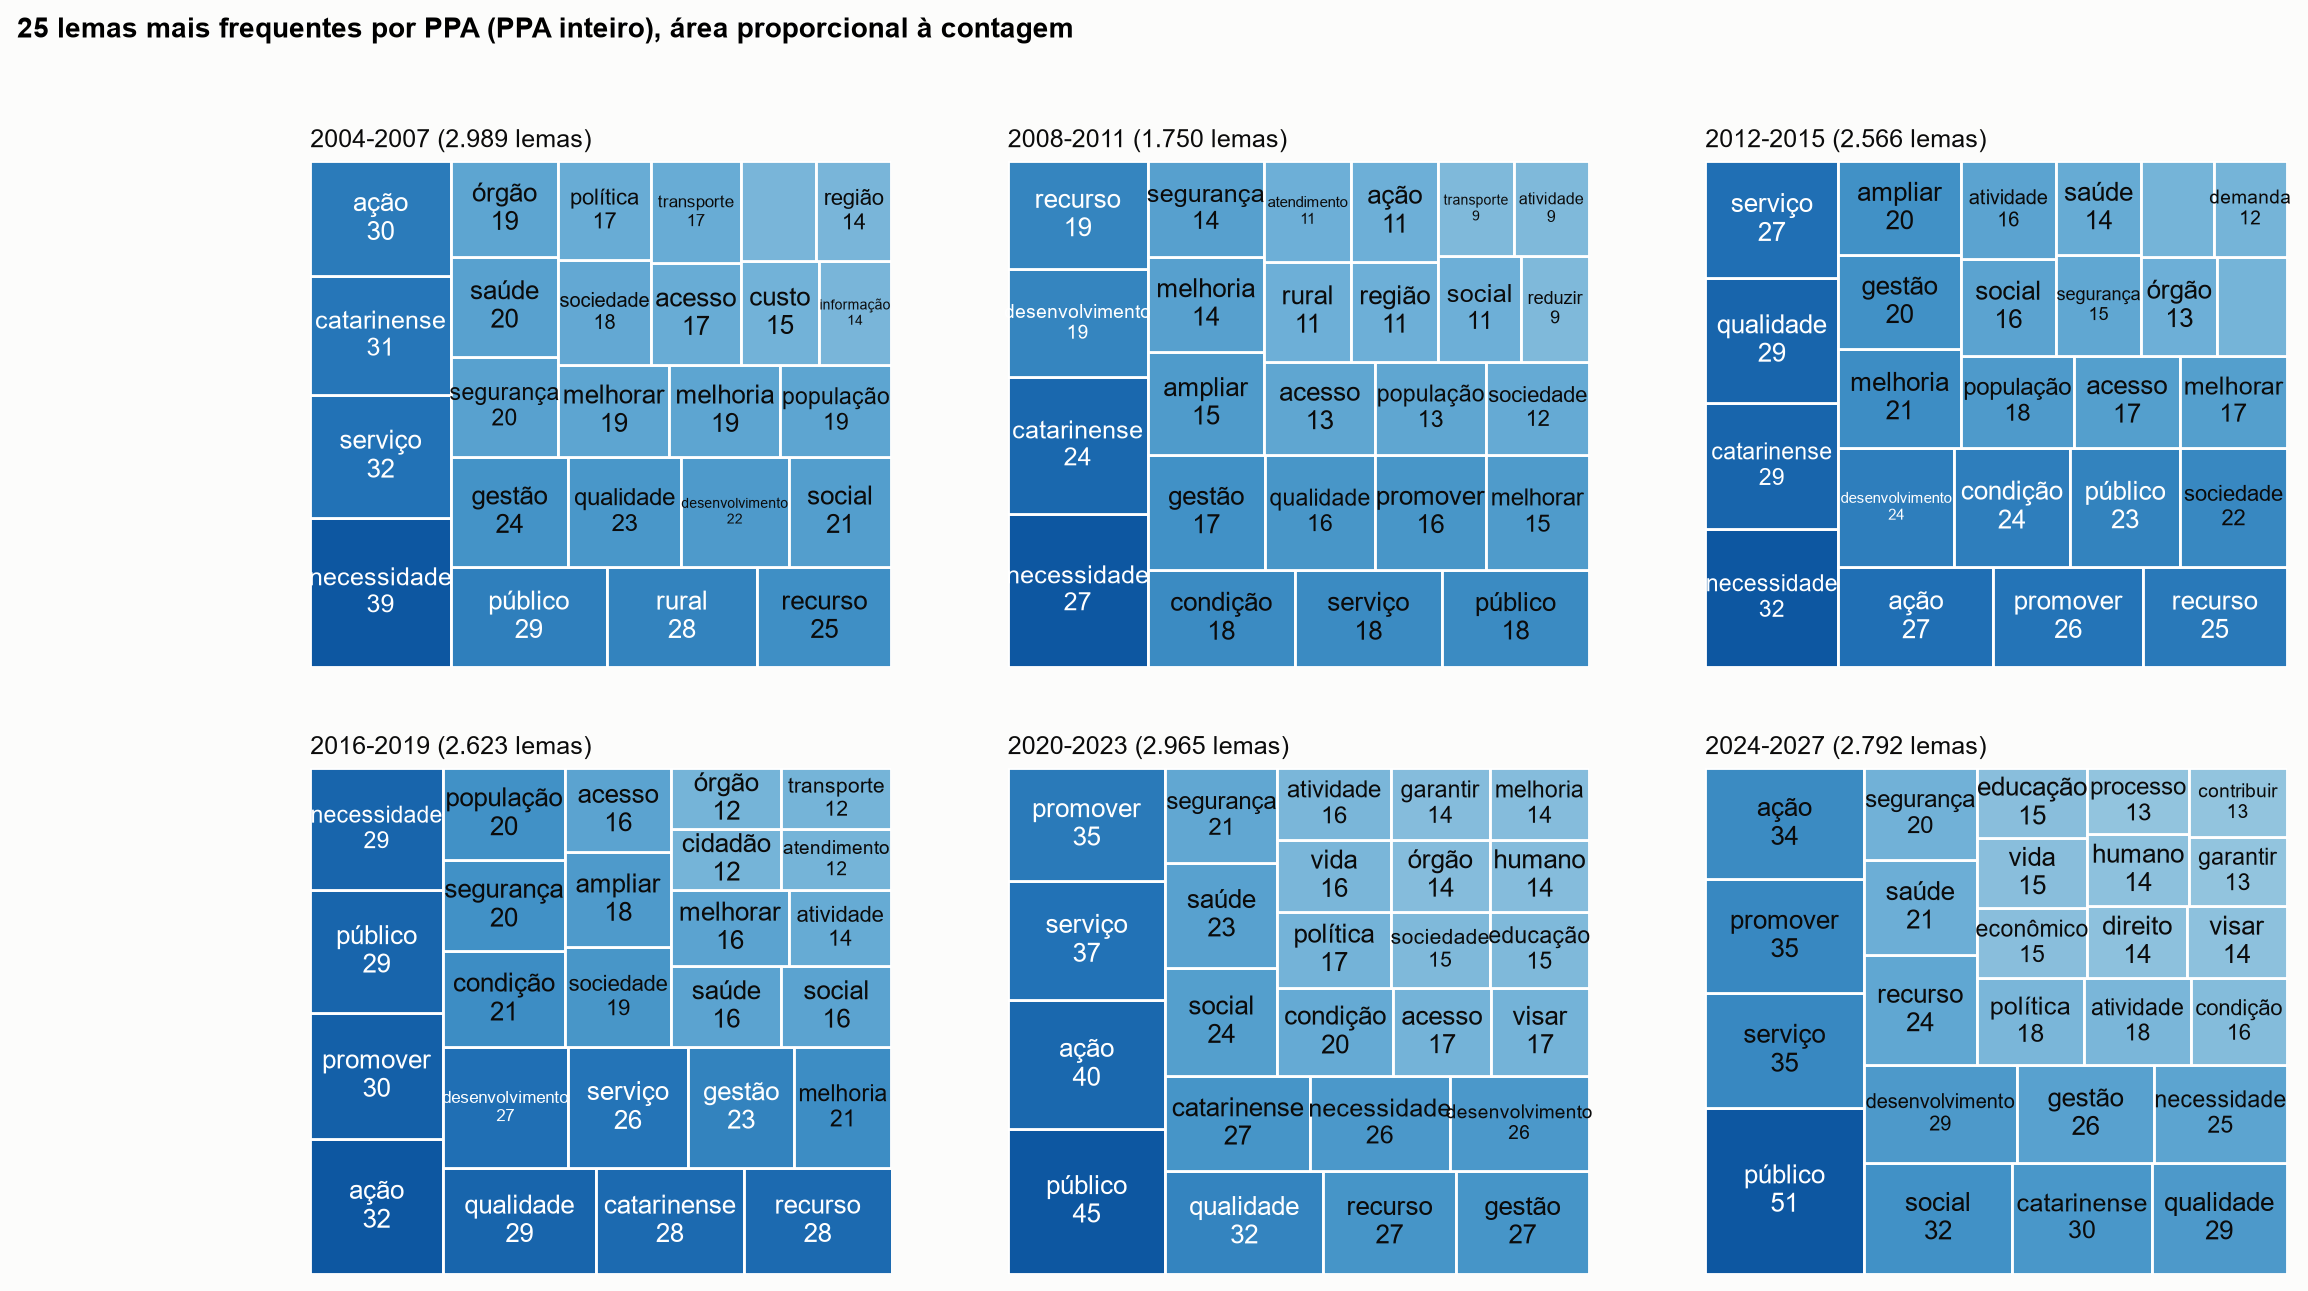

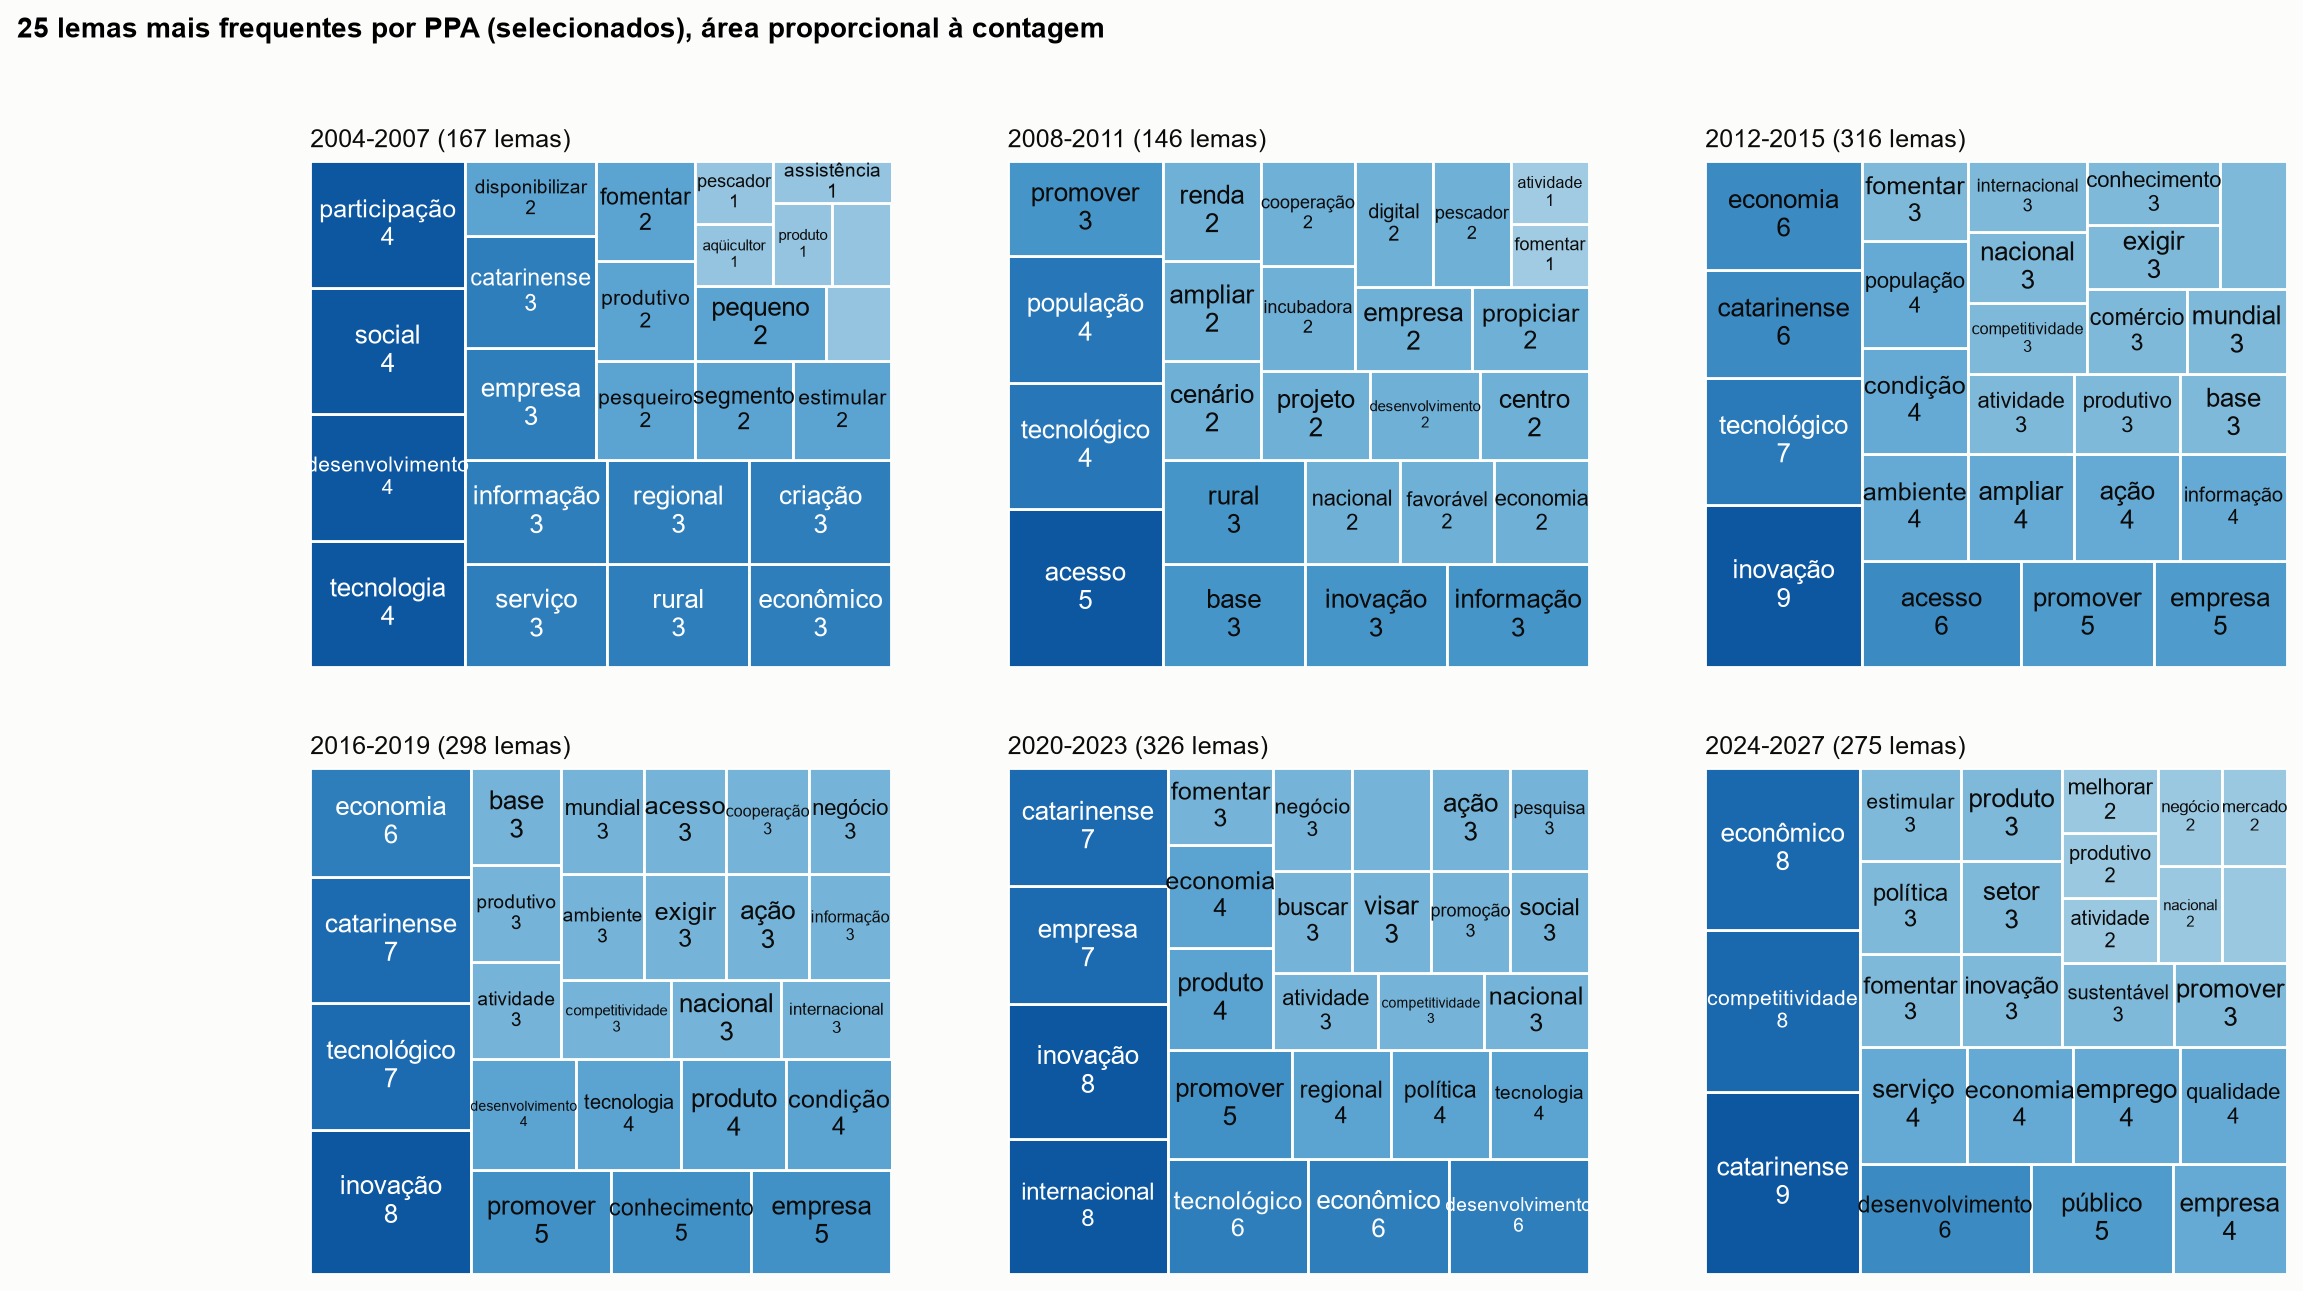

In [24]:
item9_treemap(p); item9_treemap(p, recorte="selecionados")
fig("ppa_inteiro_treemap.png", 1000)
fig("selecionados_treemap.png", 1000)

**Leitura:** no PPA inteiro dominam palavras de formato (necessidade, serviço, público, promover, ação), quase iguais em todos os PPAs. Nos selecionados, inovação e tecnológico lideram de 2012 a 2023; em 2024-2027 o topo é catarinense, competitividade e econômico.

## 10. Comparações da primeira entrega refeitas com contagem

Termos-chave do gráfico de evolução (ocorrências por mil lemas) e similaridade entre PPAs pelo cosseno dos vetores de contagem (sem TF-IDF).

figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\contagem_evolucao_termos_chave.png


figura: C:\Users\andre\OneDrive\Área de Trabalho\tcc\saidas\contagem_similaridade_entre_ppas.png


recorte,termo,2004-2007,2008-2011,2012-2015,2016-2019,2020-2023,2024-2027
selecionados,inovação,"0,0","20,5","28,5","26,8","24,5","10,9"
selecionados,competitividade,"0,0","6,8","9,5","10,1","9,2","29,1"
selecionados,digital,"0,0","13,7","6,3","0,0","0,0","0,0"
selecionados,internacional,"6,0","6,8","9,5","10,1","24,5","7,3"
selecionados,emprego,"6,0","6,8","3,2","3,4","3,1","14,5"
PPA inteiro,inovação,"0,3","1,7","3,5","3,4","3,4","2,1"
PPA inteiro,competitividade,"0,7","1,7","2,7","2,7","2,4","3,6"
PPA inteiro,digital,"0,3","1,1","0,8","0,8","0,7","1,1"
PPA inteiro,internacional,"0,7","1,7","2,7","3,8","4,0","1,8"
PPA inteiro,emprego,"2,3","1,7","0,8","0,8","0,7","1,8"


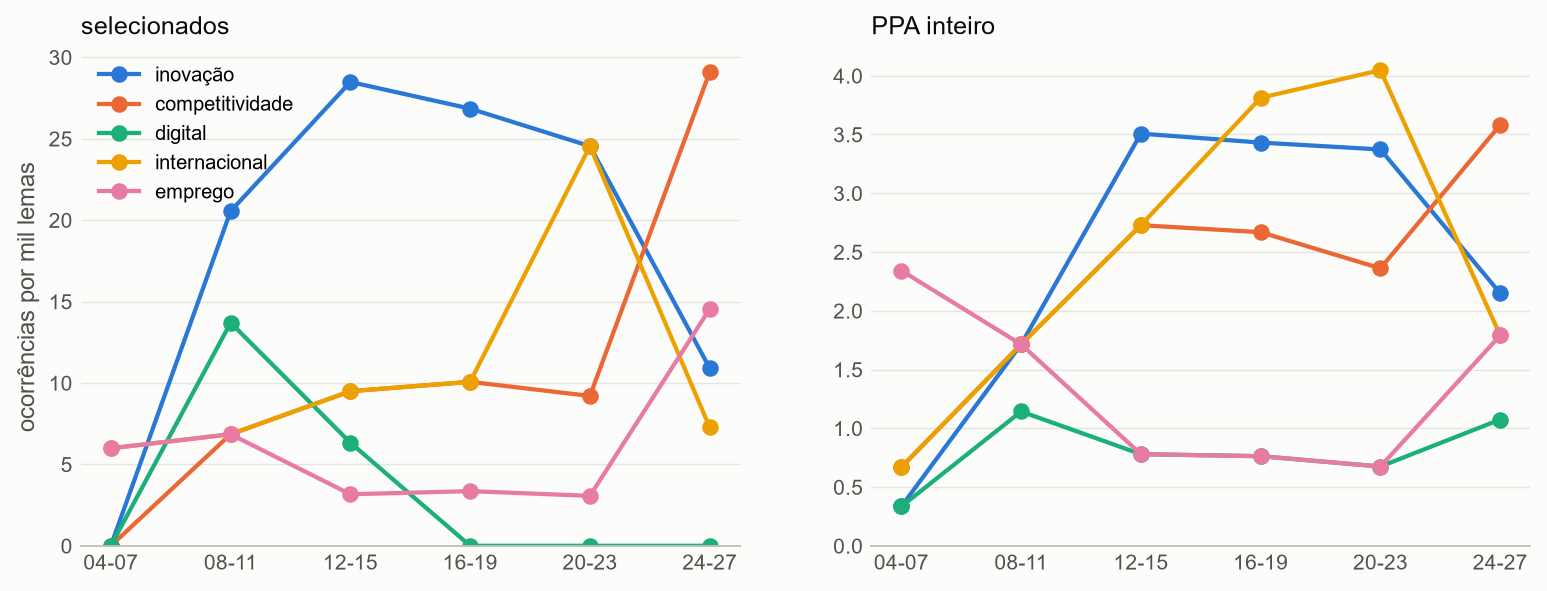

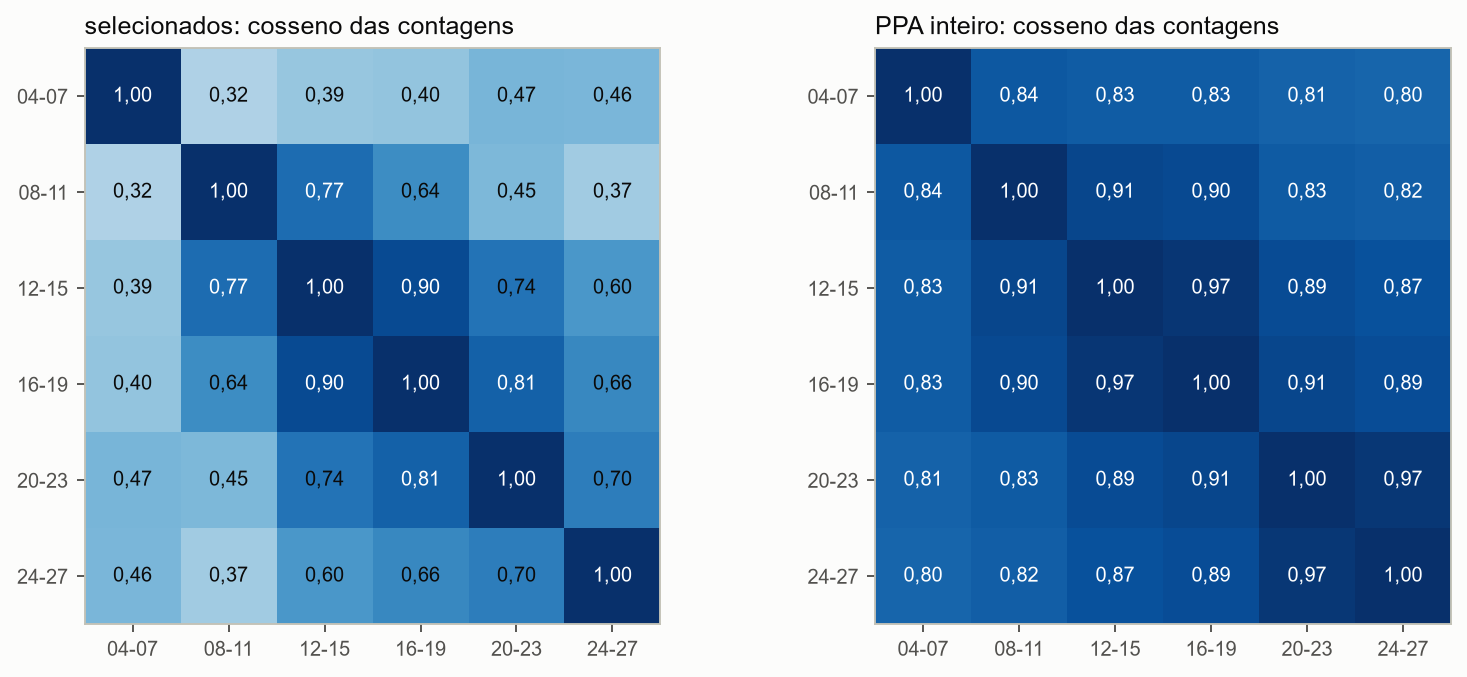

In [25]:
ev, sims = item10_refazer(p)
tabela(ev[["recorte", "termo"] + PER], 1)
fig("contagem_evolucao_termos_chave.png", 900)
fig("contagem_similaridade_entre_ppas.png", 900)

**Leitura:** a contagem reproduz o TF-IDF. Nos selecionados, a similaridade entre PPAs vizinhos dá 0,77, 0,90, 0,81 e 0,70 (TF-IDF: 0,76, 0,90, 0,81, 0,70), e o 2004-2007 continua isolado (0,32 a 0,47; TF-IDF: 0,29 a 0,44). No PPA inteiro tudo é muito parecido (0,80 a 0,97), com 2020-2023 e 2024-2027 quase iguais (0,97), coerente com a cópia de 74%. A evolução dos termos-chave é a mesma da primeira entrega: inovação forte de 2012 a 2023, digital só em 2008-2015, internacional com pico em 2020-2023, emprego e competitividade em 2024-2027. Trocar TF-IDF por contagem não muda nenhuma conclusão.

## 11. Rascunho teórico: o PPA como resultado de vários agentes

Também em `docs/rascunho-teorico-agentes.md`.

In [26]:
display(Markdown((RAIZ / "docs" / "rascunho-teorico-agentes.md").read_text(encoding="utf-8").split("## Texto")[1].split("## Pendências")[0]))



A política pública registrada em um Plano Plurianual não é a expressão de uma vontade única. O documento resulta da interação entre agentes com objetivos, informações e horizontes distintos: o governador e seu núcleo político, que definem prioridades de mandato; o órgão central de planejamento, que fixa o formato, os prazos e os limites de consolidação; as secretarias setoriais e as entidades da administração indireta, que redigem os programas e propõem as ações; e a Assembleia Legislativa, que aprova o plano e pode alterá-lo por emendas [REF sobre o processo de elaboração do PPA estadual; conferir manuais da SEF/SC]. Cada um desses agentes atua com regras próprias e com memória das rodadas anteriores, e o texto final é o estado agregado dessas decisões locais.

Essa descrição aproxima o PPA do que a literatura de sistemas complexos chama de comportamento emergente: um padrão no agregado que não foi desenhado por nenhum dos participantes e que decorre de interações descentralizadas sob restrições comuns [REF sobre emergência em sistemas adaptativos complexos]. A analogia é útil em três aspectos que os dados permitem observar. A dependência de trajetória aparece na repetição de texto entre planos consecutivos, que chega a mais de 80% dos lemas em uma das transições: o ponto de partida de cada secretaria é o programa que ela já tinha [REF sobre dependência de trajetória em políticas públicas; conferir a literatura de incrementalismo orçamentário]. A modularidade aparece na diferença entre o plano inteiro e os programas de política industrial: em 2024-2027 o plano repete três quartos do texto anterior, enquanto os programas de política industrial são reescritos junto com a criação de novas secretarias. A mudança, nesse caso, nasce em um módulo do sistema e não no centro. Por fim, o vocabulário comum que o órgão central impõe, como formato de objetivo, justificativa e indicadores, funciona como uma restrição que homogeneiza a linguagem e explica parte da similaridade alta entre planos [REF sobre isomorfismo institucional; conferir].

Para a tese, a perspectiva tem uma consequência metodológica. Se o discurso de política industrial é produto de agentes distintos, uma mudança de vocabulário pode indicar mudança de prioridade do governo, troca do órgão que redige o programa, ou simples reaproveitamento de texto. A medição precisa, portanto, separar o texto reescrito do texto herdado e registrar quem é o responsável por cada programa em cada plano, como feito neste trabalho. A mesma perspectiva conecta a análise de texto ao enquadramento de complexidade econômica: assim como as capacidades produtivas de uma região se acumulam de forma dependente da trajetória [REF: literatura de complexidade econômica e espaço de produtos já usada na tese], as capacidades de planejamento de um governo também se acumulam e restringem o que ele consegue propor em cada ciclo.

O limite dessa leitura é que o PPA mostra o resultado e não o processo. Os dados não permitem observar negociações, vetos ou emendas legislativas ao plano, e a atribuição de mudanças a agentes específicos depende de informação externa ao documento, como datas de criação de secretarias e de troca de dirigentes [verificar].



## 12. O que mudou nos resultados

- **Extração de 2008-2011 corrigida** (65 programas, não 50). Os textos dos selecionados não mudam, mas 260 milhões de outros programas (como o 0220) estavam sendo somados ao 0210: a parcela dos selecionados em 2008-2011 cai de 3,16% para **2,16% do PPA**. A série sem pessoal e emendas passa a cair em todos os PPAs: 3,07 / 2,16 / 2,08 / 1,78 / 1,37 / 1,21%.
- **PPA inteiro:** nenhum tema (inovação, competitividade, educação, indústria, empresa, léxico inteiro) muda além do acaso. A alta de competitividade é só dos programas de política industrial. "Indústria" quase não é palavra do PPA.
- **Competitividade x inovação:** nos selecionados, em 2024-2027 inovação cai na mesma medida em que competitividade sobe (soma estável); o 0200 é o caso de troca explícita. Contagens pequenas.
- **Texto reescrito:** os programas de política industrial foram reescritos em 2024-2027 (31% de cópia, contra 74% do plano) junto com a criação de novas secretarias [verificar], e a alta de competitividade está no texto novo.
- **Subações:** as de inovação e de indústria e empresa perdem peso no PPA desde 2008-2011 (para 0,41% e 0,54%). Discurso e orçamento andam em direções opostas também pelo lado das subações.
- **Público-alvo:** trabalhadores nunca são público-alvo; o 0200 passa a ter municípios como público em 2024-2027.
- **Contagem x TF-IDF:** mesmas conclusões.

Decisões do assistente desta rodada: aprovadas pelo Andrey em 13/11/2026 (ver `docs/decisoes.md`).